# 5. Smart Distractor – đáp án nhiễu hợp lý cho câu trắc nghiệm

Baseline: lấy ngẫu nhiên 3 từ cùng chủ đề. **Smart Distractor** (`BE/apps/algorithms/distractor.py`):

1. **Ứng viên:** mọi từ đã kiểm duyệt của ngôn ngữ đang học, chấm theo cosine giữa vector Word2Vec (notebook 4).
2. **Lọc:** bỏ mọi từ cũng có thể là đáp án đúng – cùng khái niệm, gần đồng nghĩa (cosine ≥ 0,88), trùng nghĩa tiếng
   Việt, trùng / chứa chữ của đáp án (biến thể vùng miền), trùng bí danh tiếng Anh; giữ cùng từ loại khi đủ.
3. **Xếp hạng:** 0,6·cos + 0,15·cùng chủ đề + 0,15·cùng từ loại + 0,1·gần cấp độ, chọn tham lam sao cho 3 đáp án
   không quá giống nhau (cosine < 0,8).

Người học tiếng Trung chỉ thấy nghĩa tiếng Việt, nên ví dụ tiếng Trung bên dưới hiện kèm nghĩa Việt.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


In [2]:
SAMPLE = 250   # số từ dùng để đánh giá

from apps.algorithms import experiments
from apps.algorithms.distractor import SYNONYM_COS, SmartDistractors, rank_candidates, vectors
from apps.learning.questions import RandomSameTopicDistractors
from apps.vocab.models import Word, WordTranslation
from apps.vocab.services import Target

vec = vectors()
print(f"{len(vec)} khái niệm có vector")
vi = dict(WordTranslation.objects.filter(language_id="vi").values_list("word_id", "text"))
texts = {c: dict(WordTranslation.objects.filter(language_id=c).values_list("word_id", "text")) for c in ("en", "zh-Hans")}
TARGET = {"en": Target("en", "en", ""), "zh-Hans": Target("zh", "zh-Hans", "hans")}

1188 khái niệm có vector


## 5.1 Ví dụ: ngẫu nhiên vs Smart

In [3]:
def show(code, slugs):
    rows = []
    for s in slugs:
        w = Word.objects.get(slug=s)
        fmt = lambda x: f"{texts[code].get(x.id, x.slug)} ({vi.get(x.id, '')})" if code != "en" else texts[code].get(x.id, x.slug)
        rows.append({"đáp án": fmt(w),
                     "ngẫu nhiên cùng chủ đề": ", ".join(fmt(x) for x in RandomSameTopicDistractors().pick(w, TARGET[code], 3)),
                     "Smart Distractor": ", ".join(fmt(x) for x in SmartDistractors().pick(w, TARGET[code], 3))})
    table(rows)

show("en", ["cat", "apple", "teacher", "bus", "red", "rain"])
print()
show("zh-Hans", ["cat", "apple", "teacher", "bus"])

đáp án   ngẫu nhiên cùng chủ đề      Smart Distractor     
-------  --------------------------  ---------------------
cat      buffalo, deer, dog          dog, horse, rabbit   
apple    corn, potato, pumpkin       fruit, pear, banana  
teacher  boy, history, reason        student, boy, class  
bus      rocket, seat belt, vehicle  station, taxi, subway
red      gray, purple, white         blue, yellow, white  
rain     leaf, volcano, wind         snow, sun, wind      



đáp án          ngẫu nhiên cùng chủ đề                       Smart Distractor                              
--------------  -------------------------------------------  ----------------------------------------------
猫 (con mèo)     恐龙 (khủng long), 海豚 (cá heo), 松鼠 (con sóc)   狗 (con chó), 马 (con ngựa), 兔子 (con thỏ)       
苹果 (quả táo)    香蕉 (quả chuối), 茄子 (quả cà tím), 木瓜 (đu đủ)  水果 (trái cây), 梨 (quả lê), 香蕉 (quả chuối)     
老师 (giáo viên)  汉语 (tiếng Trung), 书桌 (bàn học), 学期 (học kỳ)  学生 (học sinh), 男孩 (cậu bé), 班 (lớp học)       
公交车 (xe buýt)   自行车 (xe đạp), 路口 (ngã tư), 交通 (giao thông)   车站 (nhà ga), 出租车 (xe taxi), 地铁 (tàu điện ngầm)


## 5.2 Bước lọc hoạt động thế nào
12 từ gần nghĩa nhất với *cat* theo cosine, từ nào bị loại và vì sao.

In [4]:
w = Word.objects.get(slug="cat")
chosen = {c.slug for c, _ in rank_candidates(w, "en", 3)}
pool = [x for x in Word.objects.filter(slug__in=list(vec)).exclude(id=w.id) if x.id in texts["en"]]
near = sorted(pool, key=lambda x: -float(vec[w.slug] @ vec[x.slug]))[:12]
rows = []
for x in near:
    cos = float(vec[w.slug] @ vec[x.slug])
    why = ("gần đồng nghĩa" if cos >= SYNONYM_COS else "trùng nghĩa tiếng Việt" if vi.get(x.id) == vi.get(w.id)
           else "khác từ loại" if x.part_of_speech != w.part_of_speech else "")
    rows.append({"từ": texts["en"][x.id], "nghĩa": vi.get(x.id, ""), "cosine": round(cos, 3),
                 "kết quả": "✓ được chọn" if x.slug in chosen else (f"✗ {why}" if why else "· xếp sau / quá giống đáp án đã chọn")})
table(rows)

từ         nghĩa           cosine  kết quả                             
---------  --------------  ------  ------------------------------------
dog        con chó         0.8310  ✓ được chọn                         
cookie     bánh quy        0.7430  · xếp sau / quá giống đáp án đã chọn
rabbit     con thỏ         0.7060  ✓ được chọn                         
mouse      chuột máy tính  0.6970  · xếp sau / quá giống đáp án đã chọn
mouse      con chuột       0.6970  · xếp sau / quá giống đáp án đã chọn
crocodile  cá sấu          0.6760  · xếp sau / quá giống đáp án đã chọn
hot dog    xúc xích kẹp    0.6720  · xếp sau / quá giống đáp án đã chọn
squirrel   con sóc         0.6620  · xếp sau / quá giống đáp án đã chọn
hedgehog   con nhím        0.6610  · xếp sau / quá giống đáp án đã chọn
fox        con cáo         0.6530  · xếp sau / quá giống đáp án đã chọn
parrot     con vẹt         0.6470  · xếp sau / quá giống đáp án đã chọn
lizard     thằn lằn        0.6460  · xếp sau / quá giống đáp án 

## 5.3 Đánh giá trên nhiều từ

250 từ – 42s
cách chọn  distractors  mean_similarity  same_pos_rate  invalid_rate
---------  -----------  ---------------  -------------  ------------
random     750          0.4116           1.0000         0.0000      
smart      750          0.6128           1.0000         0.0000      


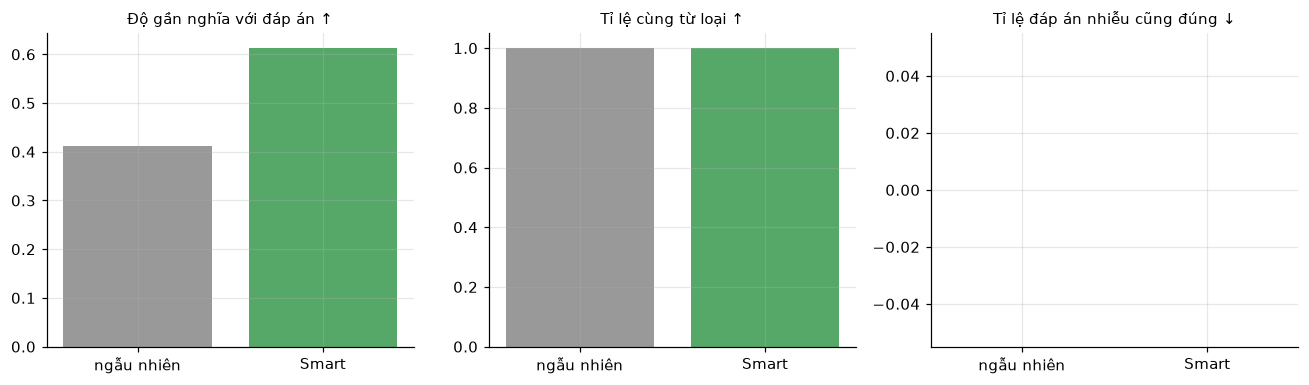

In [5]:
t0 = time.time()
run = experiments.distractor(SAMPLE)
st = run.results["stats"]
print(f"{run.results['words']} từ – {time.time() - t0:.0f}s")
table([{"cách chọn": k, **v} for k, v in st.items()])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, m, title in zip(ax, ("mean_similarity", "same_pos_rate", "invalid_rate"),
                       ("Độ gần nghĩa với đáp án ↑", "Tỉ lệ cùng từ loại ↑", "Tỉ lệ đáp án nhiễu cũng đúng ↓")):
    a.bar(["ngẫu nhiên", "Smart"], [st["random"][m], st["smart"][m]], color=["#999", "#55a868"])
    a.set_title(title, fontsize=10)
fig.tight_layout()
save(fig, "05_distractor_so_sanh")
plt.show()

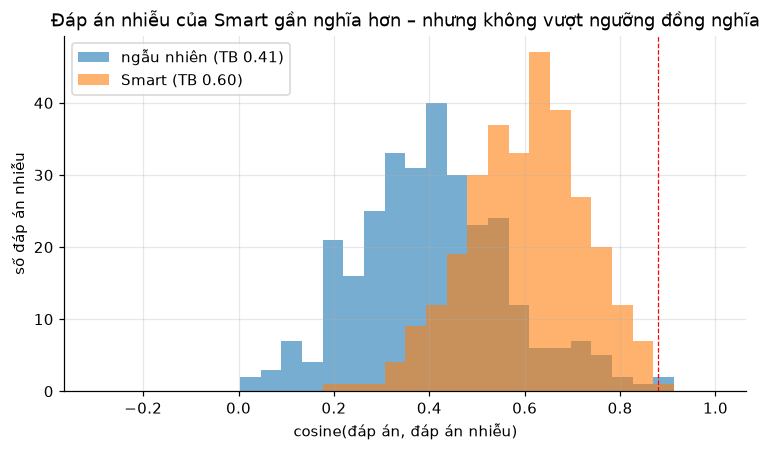

In [6]:
# phân bố cosine giữa đáp án và đáp án nhiễu (100 từ)
rng = random.Random(1)
words = rng.sample([x for x in Word.objects.filter(slug__in=list(vec)).prefetch_related("topics")], 100)
cos = {"ngẫu nhiên": [], "Smart": []}
for x in words:
    for name, prov in (("ngẫu nhiên", RandomSameTopicDistractors()), ("Smart", SmartDistractors())):
        cos[name] += [float(vec[x.slug] @ vec[p.slug]) for p in prov.pick(x, TARGET["en"], 3) if p.slug in vec]
fig, ax = plt.subplots()
for name, xs in cos.items():
    ax.hist(xs, bins=30, range=(-0.3, 1), alpha=0.6, label=f"{name} (TB {np.mean(xs):.2f})")
ax.set_xlabel("cosine(đáp án, đáp án nhiễu)")
ax.set_ylabel("số đáp án nhiễu")
ax.set_title("Đáp án nhiễu của Smart gần nghĩa hơn – nhưng không vượt ngưỡng đồng nghĩa")
ax.axvline(SYNONYM_COS, ls="--", c="red", lw=0.8)
ax.legend()
save(fig, "05_distractor_cosine")
plt.show()